# Análisis Unificado de la Producción y Exportación de Café frente a Datos Agrícolas (FAO)

## Contexto General
Este proyecto surge de la necesidad de integrar, limpiar y homologar diversas fuentes de datos para estudiar el comportamiento de la industria cafetalera a nivel global. Específicamente, se cruzan las bases de datos históricas de producción y exportaciones de la **Organización Internacional del Café (ICO)** con el amplio registro de producción de cultivos proporcionado por la **Organización de las Naciones Unidas para la Alimentación y la Agricultura (FAO)**.

El análisis abarca un horizonte temporal que inicia en 1990 y se extiende hasta 2018, permitiendo evaluar las tendencias de producción de café en comparación con la dinámica agrícola general de los países productores.

## Objetivo del Notebook
* **Limpieza y Homologación de Datos:** Resolver las inconsistencias de nomenclatura de países entre los datasets de la FAO y de la ICO para asegurar una integración del 100% de los países productores.
* **Transformación y Estructuración:** Convertir los datasets de formato ancho (*wide*) a formato largo (*long*), normalizar las unidades de medida de la industria cafetalera (sacos de 60 kg) a toneladas métricas para hacerlas comparables con los estándares de la FAO, y calcular variables derivadas como el crecimiento año con año (YoY%) y el rendimiento relativo de producción vs. exportación.
* **Análisis Exploratorio y Visualización:** Identificar a los principales productores históricos de café, analizar la correlación entre las métricas de cultivo generales y las específicas de café, y visualizar la evolución temporal y la relación estructural entre la producción y la exportación por país.

In [ ]:
""" Capistran Ortiz Diego
    Díaz del Rivero Marco Heber
    Escobar Ocaña Joaquín Junior
"""
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# 1. Cargar datasets
# Dataset de producción agrícola de FAO
df_crops = pd.read_csv('Crops_AllData_Normalized.csv', encoding='latin-1')
# Datasets de Café (ICO)
df_coffee_prod = pd.read_csv('total-production.csv')
df_coffee_exp = pd.read_csv('exports-calendar-year.csv')

In [ ]:
# 2. Inspección estructural
print("=== INFO CROPS ===")
df_crops.info()

print("\n=== INFO COFFEE PRODUCTION ===")
df_coffee_prod.info()

print("\n=== INFO COFFEE EXPORTS ===")
df_coffee_exp.info()

=== INFO CROPS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2513868 entries, 0 to 2513867
Data columns (total 11 columns):
 #   Column        Dtype  
---  ------        -----  
 0   Area Code     int64  
 1   Area          object 
 2   Item Code     int64  
 3   Item          object 
 4   Element Code  int64  
 5   Element       object 
 6   Year Code     int64  
 7   Year          int64  
 8   Unit          object 
 9   Value         float64
 10  Flag          object 
dtypes: float64(1), int64(5), object(5)
memory usage: 211.0+ MB

=== INFO COFFEE PRODUCTION ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56 entries, 0 to 55
Data columns (total 30 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   total_production  56 non-null     object 
 1   1990              56 non-null     float64
 2   1991              56 non-null     float64
 3   1992              56 non-null     float64
 4   1993              56 non-null  

In [ ]:
# Estadísticas descriptivas
display(df_crops.describe())
display(df_coffee_prod.describe())
display(df_coffee_exp.describe())

,Area Code,Item Code,Element Code,Year Code,Year,Value
count,2.513868e+06,2.513868e+06,2.513868e+06,2.513868e+06,2.513868e+06,2.359556e+06
mean,1.607881e+03,6.030662e+02,5.414220e+03,1.991644e+03,1.991644e+03,1.742925e+06
std,2.369213e+03,5.357366e+02,8.252911e+01,1.692218e+01,1.692218e+01,2.208522e+07
min,1.000000e+00,1.500000e+01,5.312000e+03,1.961000e+03,1.961000e+03,0.000000e+00
25%,9.300000e+01,2.360000e+02,5.312000e+03,1.977000e+03,1.977000e+03,4.939000e+03
50%,1.740000e+02,4.300000e+02,5.419000e+03,1.993000e+03,1.993000e+03,2.966200e+04
75%,5.102000e+03,6.560000e+02,5.510000e+03,2.006000e+03,2.006000e+03,1.487548e+05
max,5.817000e+03,1.841000e+03,5.510000e+03,2.019000e+03,2.019000e+03,2.978982e+09


,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
count,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,...,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000
mean,1664.822493,1808.333650,1759.391057,1638.653957,1666.307036,1559.240325,1844.689214,1783.235696,1944.503805,2346.139227,...,2285.246691,2536.027457,2544.203352,2701.509145,2751.702050,2674.161466,2749.779373,2855.634704,2822.753289,3052.441745
std,4152.732864,4413.782244,4996.738140,4117.062464,4151.859469,3076.885194,4304.698066,4020.792771,5195.930350,6634.240278,...,6477.171867,7919.251237,7400.186733,8153.040267,8317.499616,8092.646316,8225.952153,8526.212403,8155.437752,9465.022009
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,35.688750,51.862500,38.463500,33.867250,38.008250,41.211750,36.005500,43.115750,57.369250,57.778500,...,27.433800,34.456150,29.725625,23.509425,30.749550,35.624450,36.058675,25.401125,31.255100,28.279700
50%,437.645000,448.002000,392.046000,417.606500,344.936000,381.529000,383.417000,274.903000,430.256500,357.128500,...,348.210350,336.223600,300.132950,296.302200,222.513150,242.946900,289.537350,259.367950,241.462650,258.209300
75%,1519.850750,1567.022250,1427.149250,1456.955500,1792.530750,1875.262500,1852.624250,1452.296750,1695.846000,1786.873600,...,1279.466475,1305.025250,1518.114750,1385.361550,1020.231600,1002.430625,1019.900125,927.355150,960.599775,1237.808675
max,27285.628600,27293.493400,34603.354200,28166.978600,28192.047000,18060.202200,29196.743000,26148.004000,36760.853300,47577.806500,...,43976.812000,55428.410200,48591.828900,55418.001200,54688.966400,53304.766900,52870.587600,56788.178400,52739.863500,62924.883600


,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
count,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,...,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000
mean,1440.619154,1356.128186,1398.200664,1342.288399,1262.794600,1211.961164,1386.939034,1435.957820,1433.306410,1538.296396,...,1718.604804,1732.972228,1824.731034,1936.494461,1938.692155,2063.353181,2055.479604,2128.852433,2086.998605,2191.772802
std,3033.226941,3339.642121,3360.403996,3063.974823,2844.032482,2435.049524,2705.139085,2915.216572,3039.223544,3550.583671,...,4761.542925,4904.094137,5160.858397,5014.847747,5177.210729,6171.116656,5939.283722,6053.661326,5446.208601,6193.166996
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,45.058000,53.384750,35.803001,32.157000,28.506500,35.194750,27.221750,30.617250,31.797500,23.907250,...,14.216906,7.067483,8.435659,6.307680,5.702602,10.030269,8.766250,10.656530,8.928410,7.418941
50%,256.637000,152.753500,164.343000,188.413000,144.838000,190.424500,153.415000,163.442500,190.036500,247.839000,...,103.064927,86.731003,110.131480,108.150244,67.481614,68.389133,63.505762,71.365071,56.902176,91.408673
75%,1747.248750,1416.777250,1301.149000,1234.783250,1387.639500,1472.528000,1719.088250,1437.955750,1432.787750,1444.632750,...,1254.033953,1200.375145,1299.222401,1425.148108,1282.582329,1149.103513,933.833951,1038.491342,809.230442,954.446062
max,16935.787600,21182.761402,18790.719202,17837.747999,17273.147600,14468.432201,15250.609002,16801.260005,18144.388334,23149.203804,...,30377.981636,33166.641590,33806.009328,28549.425891,31650.562945,37335.172825,37562.846747,34269.150253,30924.567849,35382.556487


In [ ]:
# Identificación de inconsistencias
print("=== INCONSISTENCIAS ===")
print("Nulos en Cultivos FAO (df_crops):", df_crops.isnull().sum().sum())
print("Duplicados en Cultivos FAO (df_crops):", df_crops.duplicated().sum())

print("\nNulos en Producción de Café:", df_coffee_prod.isnull().sum().sum())
print("Duplicados en Producción de Café:", df_coffee_prod.duplicated().sum())

print("\nNulos en Exportación de Café:", df_coffee_exp.isnull().sum().sum())
print("Duplicados en Exportación de Café:", df_coffee_exp.duplicated().sum())

=== INCONSISTENCIAS ===
Nulos en Cultivos FAO (df_crops): 684695
Duplicados en Cultivos FAO (df_crops): 0

Nulos en Producción de Café: 0
Duplicados en Producción de Café: 0

Nulos en Exportación de Café: 0
Duplicados en Exportación de Café: 0


In [ ]:
# Desglose específico de columnas con nulos en df_crops
print("\n=== COLUMNAS CON VALORES NULOS EN CULTIVOS FAO ===")
nulos_por_columna = df_crops.isnull().sum()
print(nulos_por_columna[nulos_por_columna > 0])


=== COLUMNAS CON VALORES NULOS EN CULTIVOS FAO ===
Value    154312
Flag     530383
dtype: int64


In [ ]:
# Muestra solo las filas donde la columna 'Value' es nula (NaN)
filas_vacias_value = df_crops[df_crops['Value'].isnull()]

# Mostrar los primeros 10 registros vacíos
display(filas_vacias_value.head(10))

#    Para cada 'flag', contar cuántas filas tiene en total y cuántas de
#    esas filas tienen 'value' nulo. fillna() solo se usa para que el
#    flag en blanco (NaN, que significa "Official data") aparezca como
#    una categoría visible en la tabla, en vez de perderse en el groupby.
resumen_flag_nulos = (
    df_crops.assign(es_nulo=df_crops["Value"].isnull())
    .groupby(df_crops["Flag"].fillna("(sin flag)"))
    .agg(total_filas=("Value", "size"), valores_nulos=("es_nulo", "sum"))
)

# Porcentaje de nulos dentro de cada flag, para ver qué tan
#    CONSISTENTE es la relación (100% = el flag SIEMPRE implica nulo)
resumen_flag_nulos["pct_nulo"] = (
    resumen_flag_nulos["valores_nulos"] / resumen_flag_nulos["total_filas"] * 100
).round(2)
resumen_flag_nulos = resumen_flag_nulos.sort_values("valores_nulos", ascending=False)
print(resumen_flag_nulos)

#    LA PRUEBA CLAVE: si la suma de nulos que aportan estos flags es
#    EXACTAMENTE igual al total de nulos de 'value', queda demostrado
#    que el flag explica el 100% de los nulos (no hay nulos "sueltos"
#    sin flag asociado, ni flags con nulos que no se estén contando).
suma_por_flag = resumen_flag_nulos["valores_nulos"].sum()
total_real = df_crops["Value"].isnull().sum()

print(f"\nSuma de nulos explicados por flag: {suma_por_flag}")
print(f"Total real de nulos en value:      {total_real}")
print(f"¿Coinciden exactamente? {suma_por_flag == total_real}")

,Area Code,Area,Item Code,Item,Element Code,Element,Year Code,Year,Unit,Value,Flag
134,2,Afghanistan,711,"Anise, badian, fennel, coriander",5312,Area harvested,1961,1961,ha,NaN,M
135,2,Afghanistan,711,"Anise, badian, fennel, coriander",5312,Area harvested,1962,1962,ha,NaN,M
136,2,Afghanistan,711,"Anise, badian, fennel, coriander",5312,Area harvested,1963,1963,ha,NaN,M
137,2,Afghanistan,711,"Anise, badian, fennel, coriander",5312,Area harvested,1964,1964,ha,NaN,M
138,2,Afghanistan,711,"Anise, badian, fennel, coriander",5312,Area harvested,1965,1965,ha,NaN,M
139,2,Afghanistan,711,"Anise, badian, fennel, coriander",5312,Area harvested,1966,1966,ha,NaN,M
140,2,Afghanistan,711,"Anise, badian, fennel, coriander",5312,Area harvested,1967,1967,ha,NaN,M
141,2,Afghanistan,711,"Anise, badian, fennel, coriander",5312,Area harvested,1968,1968,ha,NaN,M
142,2,Afghanistan,711,"Anise, badian, fennel, coriander",5312,Area harvested,1969,1969,ha,NaN,M
143,2,Afghanistan,711,"Anise, badian, fennel, coriander",5312,Area harvested,1970,1970,ha,NaN,M


            total_filas  valores_nulos  pct_nulo
Flag                                            
M                125405         125405    100.00
A                721372          28753      3.99
Fc               777347            154      0.02
*                 36737              0      0.00
(sin flag)       530383              0      0.00
F                213995              0      0.00
Im               108629              0      0.00

Suma de nulos explicados por flag: 154312
Total real de nulos en value:      154312
¿Coinciden exactamente? True


In [ ]:
#Tratamiento de Valores Faltantes en df_crops
print(f"Filas iniciales en df_crops: {df_crops.shape[0]:,}")

# Eliminar filas donde la variable objetivo 'Value' es nula (NaN)
df_crops_clean = df_crops.dropna(subset=['Value']).copy()

print(f"Filas finales tras eliminar valores vacíos: {df_crops_clean.shape[0]:,}")
print(f"Nulos restantes en 'Value': {df_crops_clean['Value'].isnull().sum()}")

Filas iniciales en df_crops: 2,513,868
Filas finales tras eliminar valores vacíos: 2,359,556
Nulos restantes en 'Value': 0


In [ ]:
# Verificar redundancias en df_crops (Pares de columnas idénticas)
print("=== VERIFICACIÓN DE REDUNDANCIAS EN CULTIVOS FAO ===")
print("Columnas actuales en df_crops:")
print(df_crops.columns.tolist())

=== VERIFICACIÓN DE REDUNDANCIAS EN CULTIVOS FAO ===
Columnas actuales en df_crops:
['Area Code', 'Area', 'Item Code', 'Item', 'Element Code', 'Element', 'Year Code', 'Year', 'Unit', 'Value', 'Flag']


In [ ]:
# Tratamiento de Columnas y Categorías Redundantes
columnas_redundantes = ['Area Code', 'Item Code', 'Element Code', 'Year Code', 'Flag']

# Eliminar columnas redundantes
df_crops_clean = df_crops_clean.drop(columns=[col for col in columnas_redundantes if col in df_crops_clean.columns])

print("=== COLUMNAS RESTANTES TRAS ELIMINAR REDUNDANCIAS ===")
print(df_crops_clean.columns.tolist())
display(df_crops_clean.head())

=== COLUMNAS RESTANTES TRAS ELIMINAR REDUNDANCIAS ===
['Area', 'Item', 'Element', 'Year', 'Unit', 'Value']


,Area,Item,Element,Year,Unit,Value
0,Afghanistan,"Almonds, with shell",Area harvested,1975,ha,0.0
1,Afghanistan,"Almonds, with shell",Area harvested,1976,ha,5900.0
2,Afghanistan,"Almonds, with shell",Area harvested,1977,ha,6000.0
3,Afghanistan,"Almonds, with shell",Area harvested,1978,ha,6000.0
4,Afghanistan,"Almonds, with shell",Area harvested,1979,ha,6000.0


In [ ]:
# Estandarización de Nombres de Columnas

# Dataset FAO Crops (df_crops_clean)
df_crops_clean = df_crops_clean.rename(columns={
    'Area': 'country',
    'Item': 'item',
    'Element': 'element',
    'Year': 'year',
    'Unit': 'unit',
    'Value': 'value'
})

#  Dataset Producción de Café (df_coffee_prod)
df_coffee_prod = df_coffee_prod.rename(columns={
    'total_production': 'country'
})

# Dataset Exportaciones de Café (df_coffee_exp)
df_coffee_exp = df_coffee_exp.rename(columns={
    'exports': 'country'
})

In [ ]:
# Verificación de los nuevos nombres de columnas
print("=== NOMBRES DE COLUMNAS ESTANDARIZADOS ===")
print("FAO Crops:", df_crops_clean.columns.tolist())
print("Coffee Prod:", df_coffee_prod.columns[:3].tolist(), "...")
print("Coffee Exp:", df_coffee_exp.columns[:3].tolist(), "...")

=== NOMBRES DE COLUMNAS ESTANDARIZADOS ===
FAO Crops: ['country', 'item', 'element', 'year', 'unit', 'value']
Coffee Prod: ['country', '1990', '1991'] ...
Coffee Exp: ['country', '1990', '1991'] ...


In [ ]:
#Extraer listas de países únicos de los TRES datasets
paises_fao = sorted(df_crops_clean['country'].unique().tolist())
paises_coffee_prod = sorted(df_coffee_prod['country'].unique().tolist())
paises_coffee_exp = sorted(df_coffee_exp['country'].unique().tolist())

print(f"Total países en FAO Crops: {len(paises_fao)}")
print(f"Total países en ICO Coffee Production: {len(paises_coffee_prod)}")
print(f"Total países en ICO Coffee Exports: {len(paises_coffee_exp)}\n")

Total países en FAO Crops: 246
Total países en ICO Coffee Production: 56
Total países en ICO Coffee Exports: 56



In [ ]:
# Obtener la lista completa de las 246 entidades registradas en FAO Crops
paises_fao_completos = sorted(df_crops_clean['country'].unique().tolist())

# Imprimir la lista en bloques para revisarla fácilmente
print(f"=== LISTA COMPLETA DE ENTIDADES EN FAO CROPS ({len(paises_fao_completos)} TOTAL) ===\n")
for idx, pais in enumerate(paises_fao_completos, 1):
    print(f"{idx:3d}. {pais}")

=== LISTA COMPLETA DE ENTIDADES EN FAO CROPS (56 TOTAL) ===

  1. Angola
  2. Benin
  3. Bolivia (Plurinational State of)
  4. Brazil
  5. Burundi
  6. Cameroon
  7. Central African Republic
  8. Colombia
  9. Congo
 10. Costa Rica
 11. Cuba
 12. Côte d'Ivoire
 13. Democratic Republic of Congo
 14. Dominican Republic
 15. Ecuador
 16. El Salvador
 17. Equatorial Guinea
 18. Ethiopia
 19. Gabon
 20. Ghana
 21. Guatemala
 22. Guinea
 23. Guyana
 24. Haiti
 25. Honduras
 26. India
 27. Indonesia
 28. Jamaica
 29. Kenya
 30. Lao People's Democratic Republic
 31. Liberia
 32. Madagascar
 33. Malawi
 34. Mexico
 35. Nepal
 36. Nicaragua
 37. Nigeria
 38. Panama
 39. Papua New Guinea
 40. Paraguay
 41. Peru
 42. Philippines
 43. Rwanda
 44. Sierra Leone
 45. Sri Lanka
 46. Tanzania
 47. Thailand
 48. Timor-Leste
 49. Togo
 50. Trinidad & Tobago
 51. Uganda
 52. Venezuela
 53. Viet Nam
 54. Yemen
 55. Zambia
 56. Zimbabwe


In [ ]:
# LIMPIEZA ESPECÍFICA DE ENTIDADES Y NOMBRES EN FAO CROPS (df_crops_clean)

#  Definir lista de agregados continentales, regionales y políticos a ELIMINAR
agregados_no_paises = [
    'Africa', 'Americas', 'Asia', 'Europe', 'Oceania', 'World',
    'Australia and New Zealand', 'Caribbean', 'Central America', 'Central Asia',
    'Eastern Africa', 'Eastern Asia', 'Eastern Europe', 'Melanesia', 'Micronesia',
    'Middle Africa', 'Northern Africa', 'Northern America', 'Northern Europe',
    'Polynesia', 'South America', 'South-eastern Asia', 'Southern Africa',
    'Southern Asia', 'Southern Europe', 'Western Africa', 'Western Asia', 'Western Europe',
    'European Union (27)', 'European Union (28)', 'Least Developed Countries',
    'Land Locked Developing Countries', 'Low Income Food Deficit Countries',
    'Net Food Importing Developing Countries', 'Small Island Developing States'
]

# Filtrar df_crops_clean para conservar únicamente países/territorios individuales
df_crops_clean = df_crops_clean[~df_crops_clean['country'].isin(agregados_no_paises)].copy()

#  Definir diccionario para estandarizar Nombres Oficiales Largos y Entidades Históricas
mapa_limpieza_fao = {
    # Nombres oficiales largos a formato estándar
    'United States of America': 'USA',
    'United Republic of Tanzania': 'Tanzania',
    'Venezuela (Bolivarian Republic of)': 'Venezuela',
    'Viet Nam': 'Vietnam',
    'Bolivia (Plurinational State of)': 'Bolivia',
    "Côte d'Ivoire": 'Ivory Coast',
    'Democratic Republic of the Congo': 'DR Congo',
    'Iran (Islamic Republic of)': 'Iran',
    'Russian Federation': 'Russia',
    'Syrian Arab Republic': 'Syria',
    "Lao People's Democratic Republic": 'Laos',
    'United Kingdom of Great Britain and Northern Ireland': 'UK',
    'Trinidad and Tobago': 'Trinidad & Tobago',
    'Republic of Korea': 'South Korea',
    "Democratic People's Republic of Korea": 'North Korea',
    'Republic of Moldova': 'Moldova',
    'Brunei Darussalam': 'Brunei',

    # Entidades históricas (homologación de nombres)
    'Ethiopia PDR': 'Ethiopia',
    'Sudan (former)': 'Sudan',
    'Czechoslovakia': 'Czechia',
    'Yugoslav SFR': 'Serbia'
}

# Aplicar los reemplazos sobre df_crops_clean
df_crops_clean['country'] = df_crops_clean['country'].replace(mapa_limpieza_fao)

# 3. Verificación de resultados tras el filtrado y estandarización
paises_fao_limpios = sorted(df_crops_clean['country'].unique().tolist())

print("=== VERIFICACIÓN DE LIMPIEZA INTERNA EN FAO CROPS ===")
print(f"Total de entidades resultantes tras eliminar agregados: {len(paises_fao_limpios)}")
print("\nMuestra de países limpios en FAO Crops:")
for idx, pais in enumerate(paises_fao_limpios, 1):
    print(f"{idx:3d}. {pais}")
#print(paises_fao_limpios[:15])

=== VERIFICACIÓN DE LIMPIEZA INTERNA EN FAO CROPS ===
Total de entidades resultantes tras eliminar agregados: 207

Muestra de países limpios en FAO Crops:
  1. Afghanistan
  2. Albania
  3. Algeria
  4. Angola
  5. Antigua and Barbuda
  6. Argentina
  7. Armenia
  8. Australia
  9. Austria
 10. Azerbaijan
 11. Bahamas
 12. Bahrain
 13. Bangladesh
 14. Barbados
 15. Belarus
 16. Belgium
 17. Belgium-Luxembourg
 18. Belize
 19. Benin
 20. Bhutan
 21. Bolivia
 22. Bosnia and Herzegovina
 23. Botswana
 24. Brazil
 25. Brunei
 26. Bulgaria
 27. Burkina Faso
 28. Burundi
 29. Cabo Verde
 30. Cambodia
 31. Cameroon
 32. Canada
 33. Central African Republic
 34. Chad
 35. Chile
 36. China
 37. China, Hong Kong SAR
 38. China, Macao SAR
 39. China, Taiwan Province of
 40. China, mainland
 41. Colombia
 42. Comoros
 43. Congo
 44. Cook Islands
 45. Costa Rica
 46. Croatia
 47. Cuba
 48. Cyprus
 49. Czechia
 50. DR Congo
 51. Denmark
 52. Djibouti
 53. Dominica
 54. Dominican Republic
 55. Ecuado

In [ ]:
# COMPARACIÓN METODOLÓGICA Y LIMPIEZA DE DATASETS DE CAFÉ

# Comparar los dos datasets de café entre sí
paises_coffee_prod = sorted(df_coffee_prod['country'].unique().tolist())
paises_coffee_exp = sorted(df_coffee_exp['country'].unique().tolist())

diferencias_internas_coffee = set(paises_coffee_prod).symmetric_difference(set(paises_coffee_exp))

print("=== COMPARACIÓN INTERNA ENTRE CAFÉ PRODUCCIÓN Y EXPORTACIÓN ===")
if not diferencias_internas_coffee:
    print(" Ambos datasets de café tienen exactamente los mismos 56 países con los mismos nombres.")
else:
    print("Existen diferencias entre los datasets de café:", diferencias_internas_coffee)

=== COMPARACIÓN INTERNA ENTRE CAFÉ PRODUCCIÓN Y EXPORTACIÓN ===
 Ambos datasets de café tienen exactamente los mismos 56 países con los mismos nombres.


In [ ]:
# LIMPIEZA Y HOMOLOGACIÓN EN DATASETS DE CAFÉ

# Diccionario de reemplazo para los 5 países detectados en la auditoría
mapa_limpieza_coffee = {
    'Bolivia (Plurinational State of)': 'Bolivia',
    "Côte d'Ivoire": 'Ivory Coast',
    'Democratic Republic of Congo': 'DR Congo',
    "Lao People's Democratic Republic": 'Laos',
    'Viet Nam': 'Vietnam'
}

# Aplicar los reemplazos a ambos DataFrames de Café
df_coffee_prod['country'] = df_coffee_prod['country'].replace(mapa_limpieza_coffee)
df_coffee_exp['country'] = df_coffee_exp['country'].replace(mapa_limpieza_coffee)

# Verificación Final de Coincidencias
paises_coffee_limpios = set(df_coffee_prod['country'].unique())
paises_fao_limpios_set = set(df_crops_clean['country'].unique())

faltantes = paises_coffee_limpios - paises_fao_limpios_set

print("=== VERIFICACIÓN FINAL TRAS LIMPIEZA DE CAFÉ ===")
print(f"Países de café detectados en FAO Crops: {len(paises_coffee_limpios - faltantes)} de {len(paises_coffee_limpios)}")

if not faltantes:
    print("¡ÉXITO TOTAL! El 100% (56 de 56) de los países de café ahora coinciden perfectamente con FAO Crops.")
else:
    print("⚠️ Países pendientes de ajustar:", faltantes)

=== VERIFICACIÓN FINAL TRAS LIMPIEZA DE CAFÉ ===
Países de café detectados en FAO Crops: 56 de 56
¡ÉXITO TOTAL! El 100% (56 de 56) de los países de café ahora coinciden perfectamente con FAO Crops.


In [ ]:
#  TRANSFORMACIÓN DE DATOS: Reestructuración con melt()

# Transformar Producción de Café (df_coffee_prod)
df_prod_long = df_coffee_prod.melt(
    id_vars=['country'],
    var_name='year',
    value_name='coffee_production_60kg_bags'
)

# Transformar Exportaciones de Café (df_coffee_exp)
df_exp_long = df_coffee_exp.melt(
    id_vars=['country'],
    var_name='year',
    value_name='coffee_exports_60kg_bags'
)

#  Convertir el tipo de dato de 'year' a entero para asegurar la unión por clave
df_prod_long['year'] = df_prod_long['year'].astype(int)
df_exp_long['year'] = df_exp_long['year'].astype(int)

# Verificación de estructuras transformadas
print("=== ESTRUCTURA DESPUÉS DE MELT ===")
print(f"Producción de Café: {df_prod_long.shape} filas x columnas")
print(f"Exportaciones de Café: {df_exp_long.shape} filas x columnas\n")

display(df_prod_long.head())
print("####################################")
display(df_exp_long.head())

=== ESTRUCTURA DESPUÉS DE MELT ===
Producción de Café: (1624, 3) filas x columnas
Exportaciones de Café: (1624, 3) filas x columnas



,country,year,coffee_production_60kg_bags
0,Angola,1990,50.3450
1,Bolivia,1990,122.7770
2,Brazil,1990,27285.6286
3,Burundi,1990,487.3930
4,Ecuador,1990,1503.8150


####################################


,country,year,coffee_exports_60kg_bags
0,Angola,1990,84.3500
1,Benin,1990,0.0000
2,Bolivia,1990,156.4420
3,Brazil,1990,16935.7876
4,Burundi,1990,584.7730


In [ ]:
# TRANSFORMACIÓN DE DATOS: Normalización a Toneladas y Eliminación de Sacos

# Convertir sacos de 60 kg a toneladas métricas directamente (1 saco de 60 kg = 0.06 toneladas)
df_prod_long['coffee_production_tonnes'] = df_prod_long['coffee_production_60kg_bags'] * 0.06
df_exp_long['coffee_exports_tonnes'] = df_exp_long['coffee_exports_60kg_bags'] * 0.06

# Eliminar las columnas redundantes expresadas en sacos de 60 kg
df_prod_long = df_prod_long.drop(columns=['coffee_production_60kg_bags'])
df_exp_long = df_exp_long.drop(columns=['coffee_exports_60kg_bags'])

# Verificación de la estructura limpia en toneladas
print("=== VERIFICACIÓN EN TONELADAS (SIN SACOS DE 60KG) ===")
display(df_prod_long.head())
print("####################################")
display(df_exp_long.head())

=== VERIFICACIÓN EN TONELADAS (SIN SACOS DE 60KG) ===


,country,year,coffee_production_tonnes
0,Angola,1990,3.020700
1,Bolivia,1990,7.366620
2,Brazil,1990,1637.137716
3,Burundi,1990,29.243580
4,Ecuador,1990,90.228900


####################################


,country,year,coffee_exports_tonnes
0,Angola,1990,5.061000
1,Benin,1990,0.000000
2,Bolivia,1990,9.386520
3,Brazil,1990,1016.147256
4,Burundi,1990,35.086380


In [ ]:
# TRANSFORMACIÓN DE DATOS: Estandarización en FAO Crops

# Asegurar tipos de datos numéricos correctos
df_crops_clean['year'] = df_crops_clean['year'].astype(int)
df_crops_clean['value'] = df_crops_clean['value'].astype(float)

# Limpiar textos en 'element' e 'item' (quitar espacios extra y pasar a minúsculas)
df_crops_clean['element'] = df_crops_clean['element'].str.strip().str.lower()
df_crops_clean['item'] = df_crops_clean['item'].str.strip()

# Verificación de las unidades presentes en la FAO
unidades_fao = df_crops_clean['unit'].unique().tolist()

print("=== VERIFICACIÓN EN FAO CROPS ===")
print(f"Unidades presentes en el dataset de la FAO: {unidades_fao}")
print("Tipos de datos:")
print(df_crops_clean[['year', 'value']].dtypes)

display(df_crops_clean.head())

=== VERIFICACIÓN EN FAO CROPS ===
Unidades presentes en el dataset de la FAO: ['ha', 'hg/ha', 'tonnes']
Tipos de datos:
year       int64
value    float64
dtype: object


,country,item,element,year,unit,value
0,Afghanistan,"Almonds, with shell",area harvested,1975,ha,0.0
1,Afghanistan,"Almonds, with shell",area harvested,1976,ha,5900.0
2,Afghanistan,"Almonds, with shell",area harvested,1977,ha,6000.0
3,Afghanistan,"Almonds, with shell",area harvested,1978,ha,6000.0
4,Afghanistan,"Almonds, with shell",area harvested,1979,ha,6000.0


In [ ]:
# TRANSFORMACIÓN DE DATOS:  Filtrar únicamente Producción (Ton) en FAO Crops

# Filtrar las filas donde la métrica es producción ('production' / 'tonnes')
df_crops_prod = df_crops_clean[
    (df_crops_clean['element'] == 'production') &
    (df_crops_clean['unit'] == 'tonnes')
].copy()

#  Renombrar la columna 'value' para ser explícitos con la variable y unidad
df_crops_prod = df_crops_prod.rename(columns={'value': 'crop_production_tonnes'})

#  Seleccionar las columnas indispensables para la integración
df_crops_prod = df_crops_prod[['country', 'year', 'item', 'crop_production_tonnes']]

# Verificación
print("=== FAO CROPS: PRODUCCIÓN FILTRADA EN TONELADAS ===")
print(f"Dimensiones del dataset de producción: {df_crops_prod.shape}")
display(df_crops_prod.head())

=== FAO CROPS: PRODUCCIÓN FILTRADA EN TONELADAS ===
Dimensiones del dataset de producción: (581273, 4)


,country,year,item,crop_production_tonnes
89,Afghanistan,1975,"Almonds, with shell",0.0
90,Afghanistan,1976,"Almonds, with shell",9800.0
91,Afghanistan,1977,"Almonds, with shell",9000.0
92,Afghanistan,1978,"Almonds, with shell",12000.0
93,Afghanistan,1979,"Almonds, with shell",10500.0


In [ ]:
# TRANSFORMACIÓN DE DATOS: Crear Variables Derivadas

# 1. Unir previamente Producción y Exportación de Café para calcular Rendimiento Relativo
df_coffee_combined = pd.merge(
    df_prod_long,
    df_exp_long,
    on=['country', 'year'],
    how='inner'
)

# Calcular Rendimiento Relativo (Evitando división por cero)
# Rendimiento relativo = Producción de café / Exportaciones de café
df_coffee_combined['relative_yield_prod_vs_exp'] = np.where(
    df_coffee_combined['coffee_exports_tonnes'] > 0,
    df_coffee_combined['coffee_production_tonnes'] / df_coffee_combined['coffee_exports_tonnes'],
    np.nan
)

# 2. Calcular Crecimiento Porcentual Año a Año (YoY %) por País

# Crecimiento año a año en Producción de Café
df_coffee_combined = df_coffee_combined.sort_values(by=['country', 'year'])
df_coffee_combined['coffee_prod_yoy_growth_%'] = (
    df_coffee_combined.groupby('country')['coffee_production_tonnes']
    .pct_change() * 100
)

# Crecimiento año a año en Exportación de Café
df_coffee_combined['coffee_exp_yoy_growth_%'] = (
    df_coffee_combined.groupby('country')['coffee_exports_tonnes']
    .pct_change() * 100
)

# Crecimiento YoY en Producción Agrícola de FAO Crops
df_crops_prod = df_crops_prod.sort_values(by=['country', 'item', 'year'])
df_crops_prod['crop_prod_yoy_growth_%'] = (
    df_crops_prod.groupby(['country', 'item'])['crop_production_tonnes']
    .pct_change() * 100
)

# Verificación de variables derivadas creadas
print("=== VARIABLES DERIVADAS EN CAFÉ (Rendimiento Relativo y Crecimiento YoY) ===")
display(df_coffee_combined[['country', 'year', 'coffee_production_tonnes', 'coffee_exports_tonnes', 'relative_yield_prod_vs_exp', 'coffee_prod_yoy_growth_%']].head(10))

print("=== VARIABLES DERIVADAS EN FAO CROPS (Crecimiento YoY) ===")
display(df_crops_prod[['country', 'item', 'year', 'crop_production_tonnes', 'crop_prod_yoy_growth_%']].head(10))

=== VARIABLES DERIVADAS EN CAFÉ (Rendimiento Relativo y Crecimiento YoY) ===


,country,year,coffee_production_tonnes,coffee_exports_tonnes,relative_yield_prod_vs_exp,coffee_prod_yoy_growth_%
0,Angola,1990,3.02070,5.06100,0.596858,NaN
56,Angola,1991,4.75986,4.23006,1.125246,57.574734
112,Angola,1992,4.65120,4.81500,0.965981,-2.282840
168,Angola,1993,1.95648,2.33268,0.838726,-57.936017
224,Angola,1994,4.60812,0.49812,9.251024,135.531158
280,Angola,1995,3.72654,2.43354,1.531325,-19.131012
336,Angola,1996,4.25550,3.10986,1.368390,14.194400
392,Angola,1997,3.85980,3.02964,1.274013,-9.298555
448,Angola,1998,5.12064,3.23574,1.582525,32.665941
504,Angola,1999,3.29634,3.00684,1.096280,-35.626406


=== VARIABLES DERIVADAS EN FAO CROPS (Crecimiento YoY) ===


,country,item,year,crop_production_tonnes,crop_prod_yoy_growth_%
89,Afghanistan,"Almonds, with shell",1975,0.0,NaN
90,Afghanistan,"Almonds, with shell",1976,9800.0,inf
91,Afghanistan,"Almonds, with shell",1977,9000.0,-8.163265
92,Afghanistan,"Almonds, with shell",1978,12000.0,33.333333
93,Afghanistan,"Almonds, with shell",1979,10500.0,-12.500000
94,Afghanistan,"Almonds, with shell",1980,9900.0,-5.714286
95,Afghanistan,"Almonds, with shell",1981,8000.0,-19.191919
96,Afghanistan,"Almonds, with shell",1982,11000.0,37.500000
97,Afghanistan,"Almonds, with shell",1983,9700.0,-11.818182
98,Afghanistan,"Almonds, with shell",1984,10500.0,8.247423


In [ ]:
# Unión de las coincidencias con los datasets Crops_production y El dataset del incremento de cafe año con año.
df_unified = pd.merge(
    df_crops_clean,
    df_coffee_combined,
    on=['country', 'year'],
    how='right'
)

print("=== DATAFRAME UNIFICADO POR PAÍS Y AÑO ===")
print(f"Dimensiones del DataFrame unificado: {df_unified.shape}")
display(df_unified.head(10))

=== DATAFRAME UNIFICADO POR PAÍS Y AÑO ===
Dimensiones del DataFrame unificado: (296259, 11)


,country,item,element,year,unit,value,coffee_production_tonnes,coffee_exports_tonnes,relative_yield_prod_vs_exp,coffee_prod_yoy_growth_%,coffee_exp_yoy_growth_%
0,Angola,Bananas,Area harvested,1990,ha,26421.0,3.0207,5.061,0.596858,NaN,NaN
1,Angola,Bananas,Yield,1990,hg/ha,102191.0,3.0207,5.061,0.596858,NaN,NaN
2,Angola,Bananas,Production,1990,tonnes,270000.0,3.0207,5.061,0.596858,NaN,NaN
3,Angola,"Bastfibres, other",Area harvested,1990,ha,1107.0,3.0207,5.061,0.596858,NaN,NaN
4,Angola,"Bastfibres, other",Yield,1990,hg/ha,9575.0,3.0207,5.061,0.596858,NaN,NaN
5,Angola,"Bastfibres, other",Production,1990,tonnes,1060.0,3.0207,5.061,0.596858,NaN,NaN
6,Angola,"Beans, dry",Area harvested,1990,ha,121000.0,3.0207,5.061,0.596858,NaN,NaN
7,Angola,"Beans, dry",Yield,1990,hg/ha,2727.0,3.0207,5.061,0.596858,NaN,NaN
8,Angola,"Beans, dry",Production,1990,tonnes,33000.0,3.0207,5.061,0.596858,NaN,NaN
9,Angola,"Cashew nuts, with shell",Area harvested,1990,ha,3000.0,3.0207,5.061,0.596858,NaN,NaN


In [ ]:
# Configuración de estilo de visualización
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

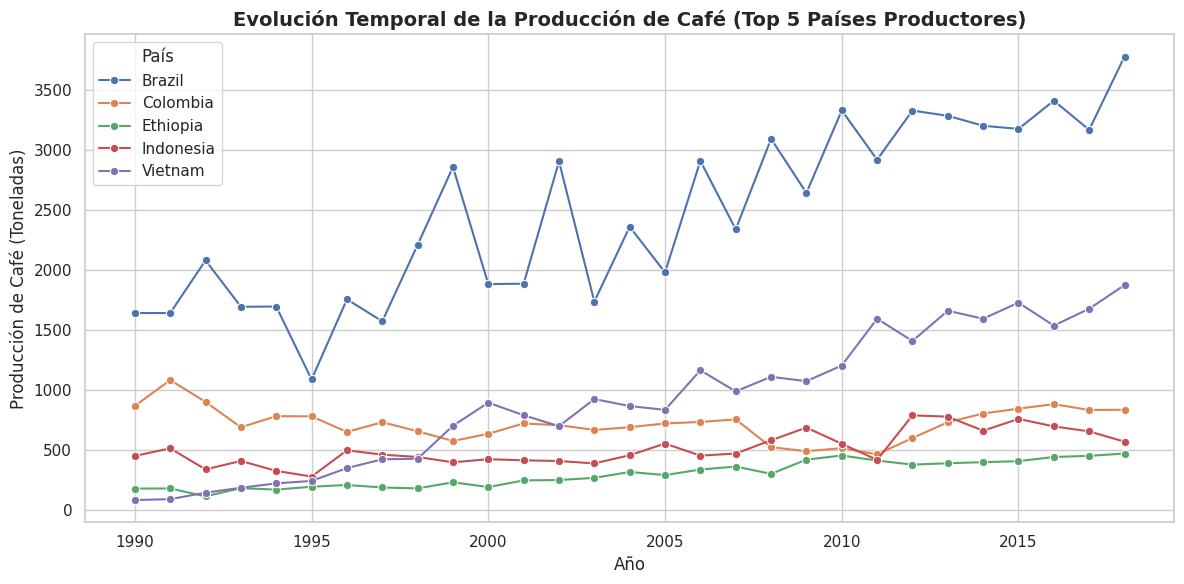

In [ ]:
# 1. Identificar los principales productores históricos de café en toneladas acumuladas
top_coffee_producers = (
    df_coffee_combined.groupby('country')['coffee_production_tonnes']
    .sum()
    .nlargest(5)
    .index
    .tolist()
)

# Filtrar datos de estos países para graficar series de tiempo
df_top_trends = df_coffee_combined[df_coffee_combined['country'].isin(top_coffee_producers)]

# Graficar Serie de Tiempo
fig_ts, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(
    data=df_top_trends,
    x='year',
    y='coffee_production_tonnes',
    hue='country',
    marker='o',
    ax=ax
)
ax.set_title("Evolución Temporal de la Producción de Café (Top 5 Países Productores)", fontsize=14, fontweight='bold')
ax.set_xlabel("Año")
ax.set_ylabel("Producción de Café (Toneladas)")
ax.legend(title="País")
plt.tight_layout()
plt.show()

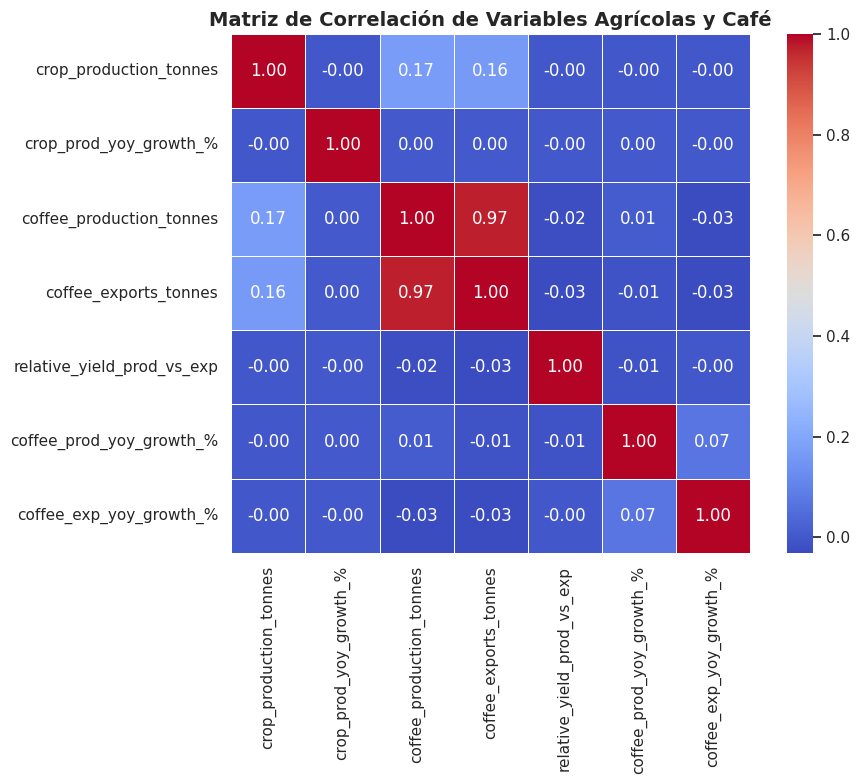

In [ ]:
# 2. Correlación entre variables numéricas en el dataset unificado
columnas_corr = [
    'crop_production_tonnes',
    'crop_prod_yoy_growth_%',
    'coffee_production_tonnes',
    'coffee_exports_tonnes',
    'relative_yield_prod_vs_exp',
    'coffee_prod_yoy_growth_%',
    'coffee_exp_yoy_growth_%'
]

corr_matrix = df_unified[columnas_corr].corr() # Obtener correlación

# Graficar Mapa de Calor (Heatmap)
fig_heatmap, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5,
    square=True,
    ax=ax
)
ax.set_title("Matriz de Correlación de Variables Agrícolas y Café", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

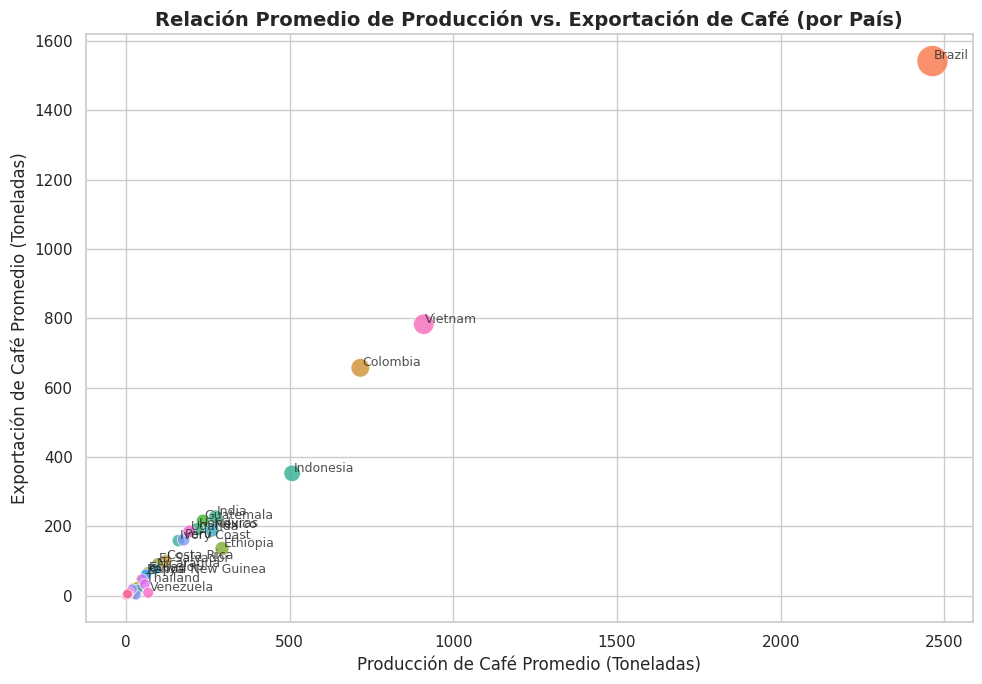

In [ ]:
# 3. Relación entre Producción y Exportaciones de Café mediante un Scatter Plot
# Agrupado por país para visualizar la media general del comportamiento histórico
df_country_avg = df_coffee_combined.groupby('country')[['coffee_production_tonnes', 'coffee_exports_tonnes']].mean().reset_index()

fig_scatter, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(
    data=df_country_avg,
    x='coffee_production_tonnes',
    y='coffee_exports_tonnes',
    hue='country',
    size='coffee_production_tonnes',
    sizes=(50, 500),
    legend=False,
    alpha=0.8,
    ax=ax
)

# Agregar etiquetas a los países con producción significativa para evitar saturación
for idx, row in df_country_avg.iterrows():
    if row['coffee_production_tonnes'] > 100 or row['coffee_exports_tonnes'] > 100: # Filtro para aquello países con producciones o exportaciones mayores a 100.
        ax.text(
            row['coffee_production_tonnes'] + 5,
            row['coffee_exports_tonnes'] + 5,
            row['country'],
            fontsize=9,
            alpha=0.8
        )

ax.set_title("Relación Promedio de Producción vs. Exportación de Café (por País)", fontsize=14, fontweight='bold')
ax.set_xlabel("Producción de Café Promedio (Toneladas)")
ax.set_ylabel("Exportación de Café Promedio (Toneladas)")
plt.tight_layout()
plt.show()